# 02 - ERP distortion as a function of latitude

Observation first, interpretation second: we measure how error varies with latitude, then use a rotation control to separate *distortion in the model input* from *scene content* (floors/ceilings always sit at the poles of upright indoor panoramas).

In [1]:
import os, sys, json
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
RES = 'results/midas_dpt_hybrid_synthetic'   # change to e.g. results/dap_stanford2d3d after running DAP
REP = os.path.join(RES, 'report_align-all')
def show(p, w=900):
    p = os.path.join(RES, p) if not os.path.exists(p) else p
    display(Image(filename=p, width=w)) if os.path.exists(p) else print('missing', p)

## How strong is the ERP distortion?
Horizontal stretch 1/cos(phi): x1.15 at 30 deg, x1.41 at 45, x2 at 60, x3.9 at 75.

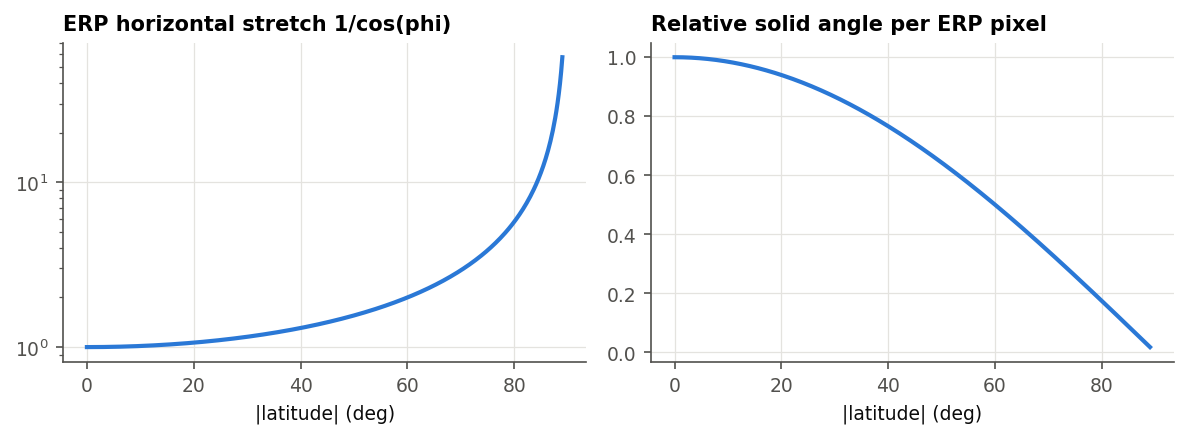

In [2]:
show('report_align-all/erp_distortion.png')

## Error vs latitude (baseline)

**eval alignment fitted on: all**

,abs_rel,rmse,d1,mae,err_var,pct_bad,n
band,,,,,,,
all,0.163040,0.576516,0.743198,0.370909,0.207542,57.953922,524288.0
0-15,0.242677,0.985460,0.531205,0.711420,0.510093,71.311016,88064.0
15-30,0.206820,0.767175,0.601164,0.562679,0.287124,70.077805,86016.0
30-45,0.141514,0.387909,0.801413,0.306790,0.061542,57.189941,88064.0
45-60,0.116200,0.253180,0.873243,0.207925,0.022659,44.270786,88064.0
60-75,0.125896,0.248092,0.858882,0.206529,0.022982,46.971348,86016.0
75-90,0.145286,0.272993,0.792666,0.230747,0.027561,57.929177,88064.0


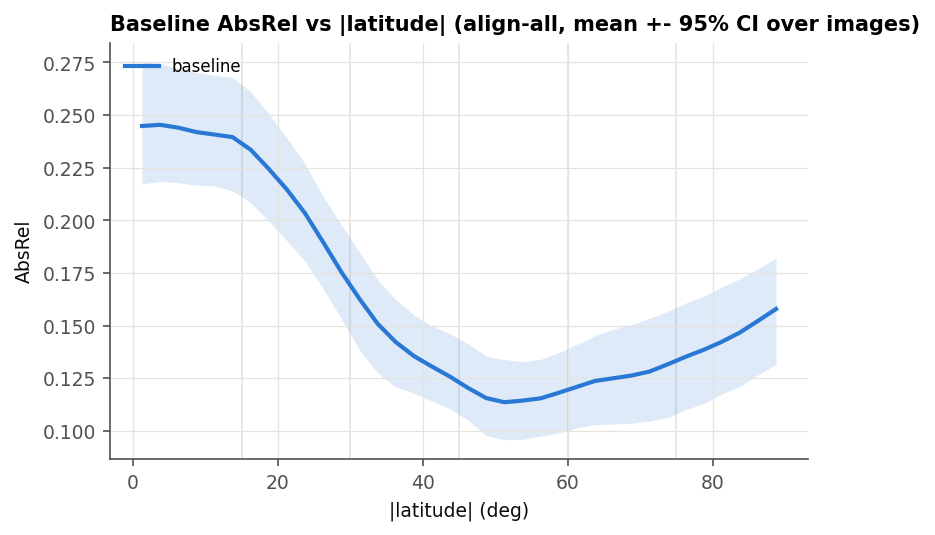

**eval alignment fitted on: equatorial**

,abs_rel,rmse,d1,mae,err_var,pct_bad,n
band,,,,,,,
all,0.267634,0.666149,0.538403,0.507778,0.255356,72.012806,524288.0
0-15,0.153520,0.608839,0.784724,0.433138,0.211893,56.905915,88064.0
15-30,0.147709,0.536098,0.788631,0.390532,0.153831,56.026495,86016.0
30-45,0.204860,0.554318,0.648125,0.440166,0.166351,68.078992,88064.0
45-60,0.295484,0.649230,0.442993,0.535020,0.232596,77.021872,88064.0
60-75,0.372639,0.709825,0.322412,0.597220,0.277205,83.561198,86016.0
75-90,0.431247,0.753482,0.244330,0.649946,0.285667,90.379156,88064.0


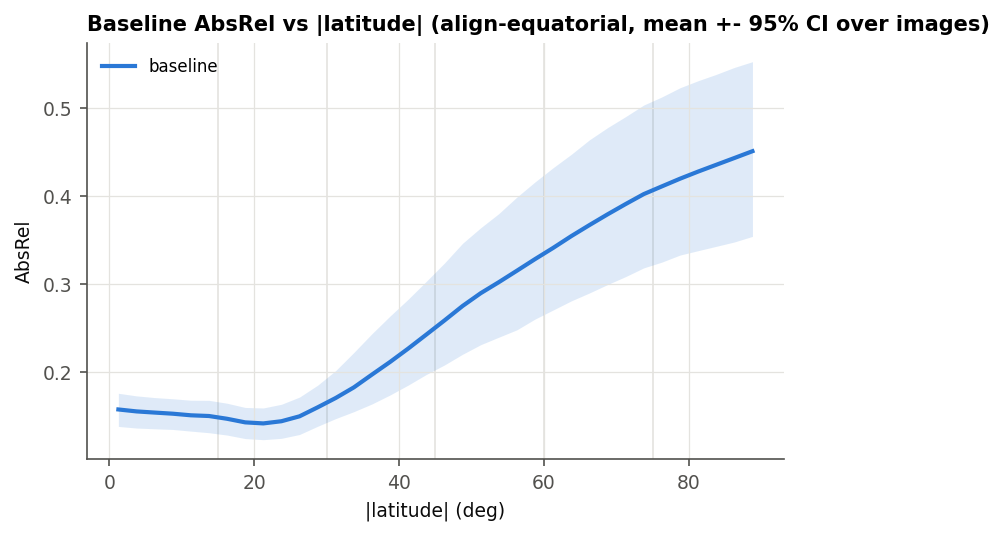

In [3]:
for r in ['all', 'equatorial']:
    display(Markdown(f'**eval alignment fitted on: {r}**'))
    display(pd.read_csv(os.path.join(RES, f'report_align-{r}', f'latitude_bands_align-{r}.csv'), index_col=0))
    show(f'report_align-{r}/abs_rel_vs_abs_latitude_align-{r}.png', 650)

## Where does degradation start? (paired bootstrap vs the |lat|<15 reference)

In [4]:
on = json.load(open(os.path.join(REP, 'onset_align-all.json')))
print('onset |lat|:', on['onset_abs_lat'])
pd.DataFrame(on['bins']).round(4)

onset |lat|: None


,abs_lat,mean_diff,ci_lo,ci_hi,ratio_to_ref,significant
0,1.25,0.0021,-0.0033,0.0091,1.0085,False
1,3.75,0.0026,0.0004,0.0050,1.0109,True
2,6.25,0.0013,-0.0005,0.0033,1.0053,False
3,8.75,-0.0008,-0.0038,0.0016,0.9966,False
4,11.25,-0.0020,-0.0051,0.0008,0.9918,False
5,13.75,-0.0032,-0.0079,0.0011,0.9868,False
6,16.25,-0.0092,-0.0173,-0.0023,0.9621,False
7,18.75,-0.0183,-0.0291,-0.0087,0.9245,False
8,21.25,-0.0281,-0.0402,-0.0166,0.8841,False
9,23.75,-0.0394,-0.0520,-0.0270,0.8377,False


## Per-pixel mean error

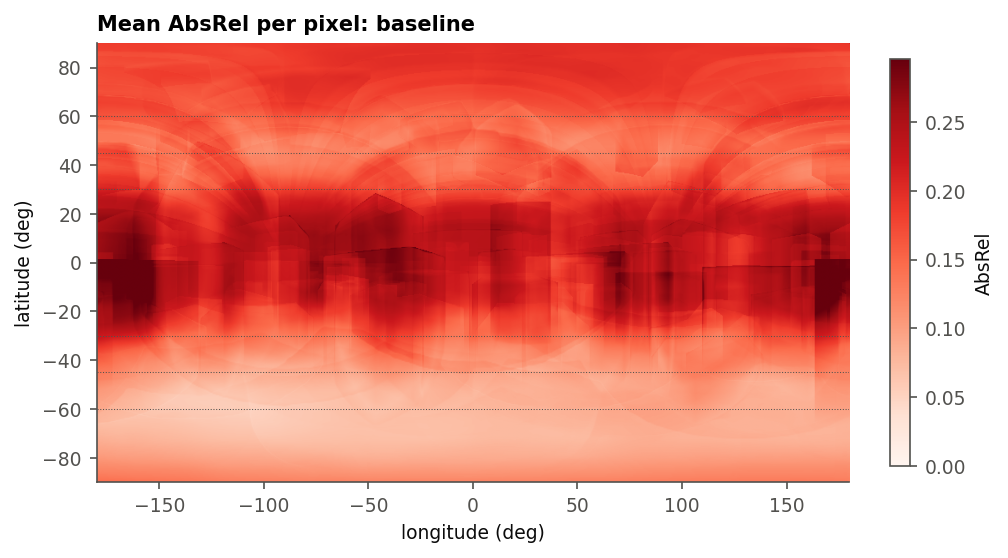

In [5]:
show('report_align-all/heatmap_baseline.png')

## Control: content vs latitude
The same panoramas rotated by pitch 0/30/60/90 deg (GT rotated identically). Left: error against latitude in the image the model saw. Right: against latitude of the content in the upright scene. The GT alignment of the relative model is fitted on (a) all pixels, (b) the input's equator (the situation of inference-time correction, which trusts the equator), (c) the content's equator.

### GT alignment fitted on: view_equatorial

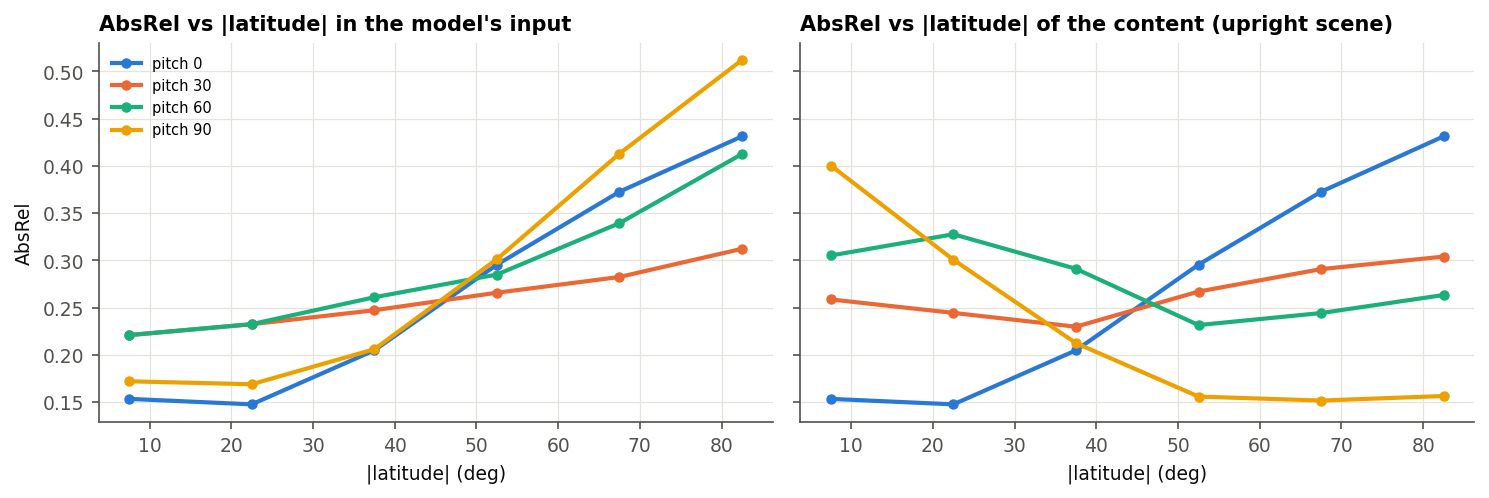

Within one pitch, same image and content band: % change of AbsRel when the content sits further from the input equator (median is robust to the few degenerate fits):

,pitch,delta_view_deg,mean,median,count
0,30,15.0,5.73,-6.48,144
1,30,30.0,27.72,-0.11,120
2,30,45.0,52.17,11.72,96
3,30,60.0,51.68,32.81,48
4,60,15.0,5.51,-1.50,144
5,60,30.0,18.34,3.90,120
6,60,45.0,34.86,5.06,120
7,60,60.0,78.37,31.72,96
8,60,75.0,119.30,82.84,48
9,90,15.0,3.61,1.93,120


### GT alignment fitted on: all

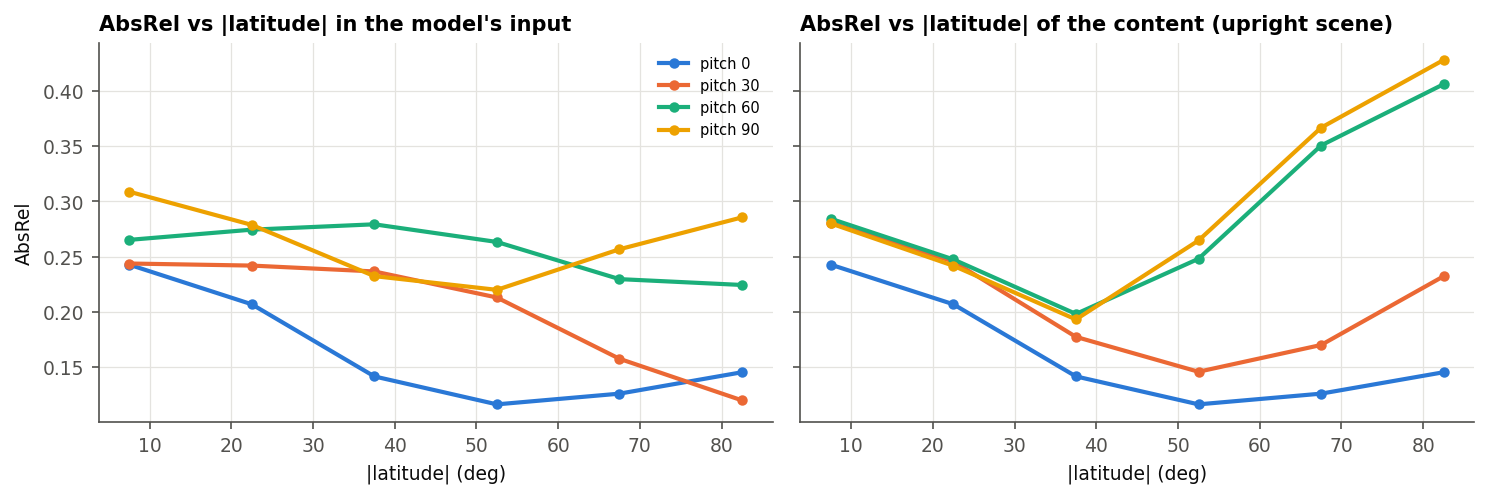

Within one pitch, same image and content band: % change of AbsRel when the content sits further from the input equator (median is robust to the few degenerate fits):

,pitch,delta_view_deg,mean,median,count
0,30,15.0,-4.68,-10.55,144
1,30,30.0,-6.66,-18.46,120
2,30,45.0,-19.02,-27.07,96
3,30,60.0,-15.07,-26.57,48
4,60,15.0,5.90,-0.06,144
5,60,30.0,10.54,-4.26,120
6,60,45.0,8.34,-11.36,120
7,60,60.0,9.95,-14.00,96
8,60,75.0,13.89,-12.49,48
9,90,15.0,10.32,-5.42,120


### GT alignment fitted on: content_equatorial

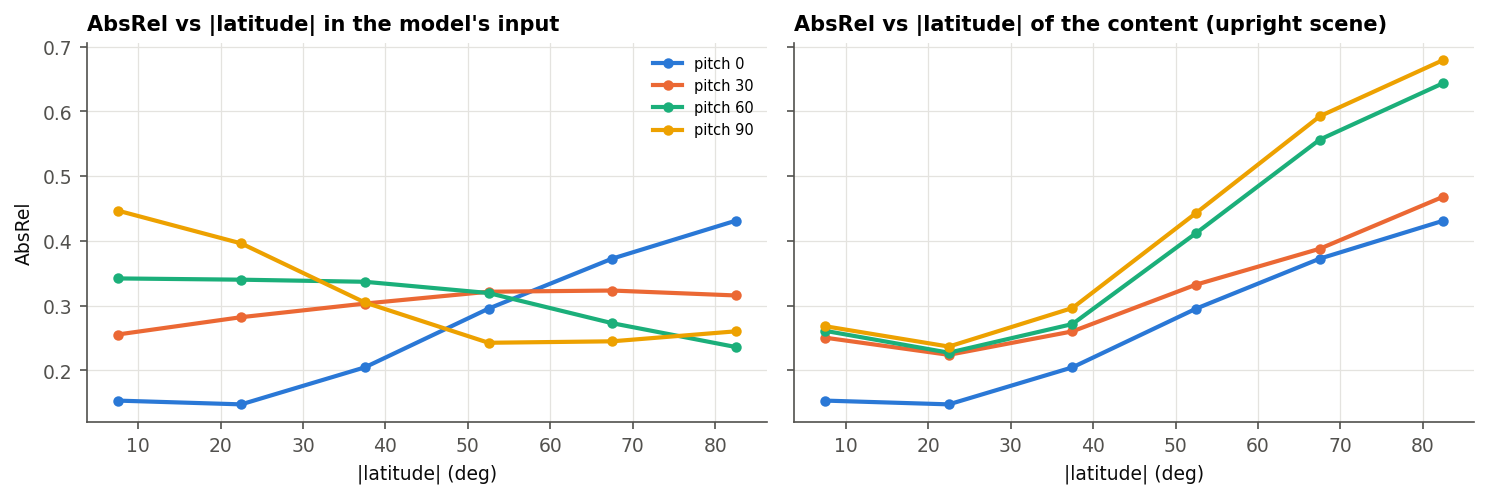

Within one pitch, same image and content band: % change of AbsRel when the content sits further from the input equator (median is robust to the few degenerate fits):

,pitch,delta_view_deg,mean,median,count
0,30,15.0,-4.61,-6.29,144
1,30,30.0,-6.16,-15.20,120
2,30,45.0,-7.94,-21.27,96
3,30,60.0,-2.10,-14.67,48
4,60,15.0,3.22,0.60,144
5,60,30.0,6.76,-2.25,120
6,60,45.0,0.27,-10.43,120
7,60,60.0,0.51,-9.84,96
8,60,75.0,-0.50,-15.84,48
9,90,15.0,-2.84,-6.95,120


In [6]:
for a in ['view_equatorial', 'all', 'content_equatorial']:
    d = os.path.join(RES, 'latitude_control', f'align-{a}')
    display(Markdown(f'### GT alignment fitted on: {a}'))
    show(os.path.join(d, 'latitude_control.png'), 900)
    display(Markdown('Within one pitch, same image and content band: % change of AbsRel when the content sits further from the input equator (median is robust to the few degenerate fits):'))
    display(pd.read_csv(os.path.join(d, 'control_within_pitch_view_effect.csv')).round(2))

## Why does the hybrid work? Signed polar bias of each view (8 images)

In [7]:
p = os.path.join(RES, 'bias_analysis_summary.csv')
pd.read_csv(p, header=[0, 1], index_col=[0, 1]) if os.path.exists(p) else print('run: python -m experiments.bias_analysis')

signed_log_err         abs_rel        
                                  mean     std    mean     std
pole  view                                                    
north baseline                  0.1615  0.4281  0.4721  0.4286
      hybrid_final              0.1073  0.1945  0.1924  0.1766
      rotation_pitch+90         0.0670  0.2565  0.2125  0.2119
      rotation_pitch-90        -0.0020  0.1445  0.1350  0.0480
      tangent_lat+90            0.2440  0.3424  0.4282  0.3963
south baseline                 -0.4047  0.2061  0.3169  0.1451
      hybrid_final              0.0358  0.2302  0.1870  0.1465
      rotation_pitch+90         0.2939  0.3273  0.4858  0.3389
      rotation_pitch-90         0.4145  0.1749  0.5491  0.2657
      tangent_lat-90           -0.2979  0.3145  0.2691  0.1655